In [4]:
import pandas as pd

df = pd.read_csv("../data/processed/online_retail_propre.csv",
                 parse_dates=["InvoiceDate"])

clients = (df.groupby("CustomerID")
             .agg(premier_achat=("InvoiceDate", "min"),
                  nb_commandes=("InvoiceNo", "nunique"),
                  ca_total=("CA", "sum"))
             .reset_index())

n_avant = len(df)
df_m = df.merge(clients, on="CustomerID", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

C:\Users\andya\AppData\Local\Temp\ipykernel_14408\3534649900.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/online_retail_propre.csv",


524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64


CA mensuel

In [ ]:
import matplotlib.pyplot as plt

mensuel = df_m.set_index("InvoiceDate").resample("MS")["CA"].sum()
print(mensuel)

mensuel.plot(kind="line", marker="o", figsize=(10, 4),
             title="CA mensuel")
plt.ylabel("CA")
plt.show()

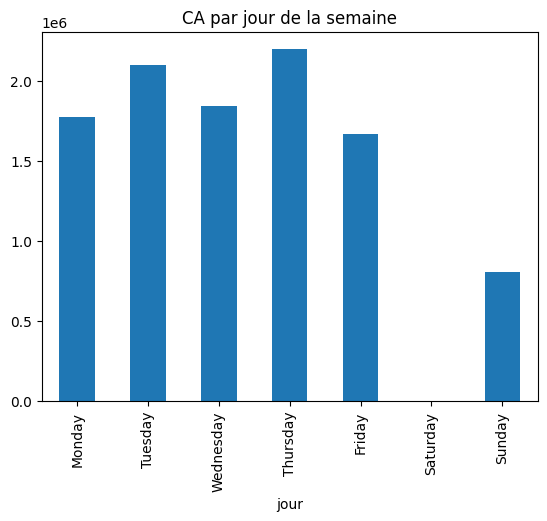

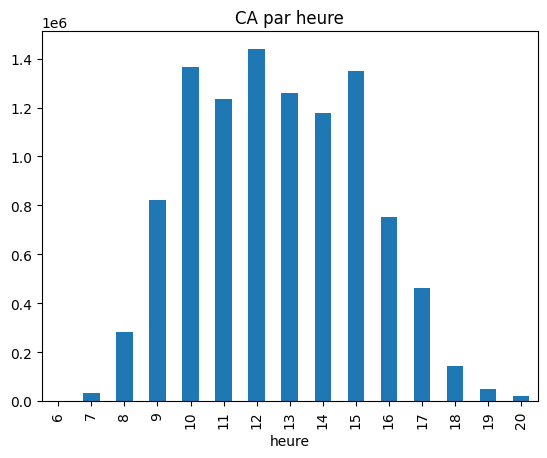

In [6]:
import matplotlib.pyplot as plt

ordre = ["Monday", "Tuesday", "Wednesday", "Thursday",
         "Friday", "Saturday", "Sunday"]

df_m["jour"] = df_m["InvoiceDate"].dt.day_name()
df_m["heure"] = df_m["InvoiceDate"].dt.hour

df_m.groupby("jour")["CA"].sum().reindex(ordre).plot(
    kind="bar", title="CA par jour de la semaine")
plt.show()

df_m.groupby("heure")["CA"].sum().plot(
    kind="bar", title="CA par heure")
plt.show()

In [10]:
cont = {
    "Europe": ["United Kingdom", "France", "Germany", "EIRE", "Spain",
               "Netherlands", "Belgium", "Switzerland", "Portugal", "Italy",
               "Norway", "Finland", "Sweden", "Austria", "Denmark", "Poland",
               "Iceland", "Greece", "Malta", "Lithuania", "Czech Republic",
               "Cyprus", "Channel Islands", "European Community"],
    "Amérique du Nord": ["USA", "Canada"],
    "Amérique du Sud": ["Brazil"],
    "Océanie": ["Australia"],
    "Asie": ["Japan", "Hong Kong", "Singapore", "Israel", "Lebanon",
             "Bahrain", "United Arab Emirates", "Saudi Arabia"],
    "Afrique": ["RSA"],
    "Inconnu": ["Unspecified"],
}

continents = pd.DataFrame(
    [(pays, c) for c, pays in cont.items() for pays in pays],
    columns=["Country", "Continent"],
)

n_avant = len(df)
df_m = df.merge(continents, on="Country", how="left",
                validate="m:1", indicator=True)

print(n_avant, "→", len(df_m))
print(df_m["_merge"].value_counts())

524876 → 524876
_merge
both          524876
left_only          0
right_only         0
Name: count, dtype: int64
